<h2>
  Vignette 04: Platform-Agnostic Workflows<br>
  <span style="font-size: 12px; font-weight: normal; display: block">
    <i>"The rules may be elusive, but all pieces are the same" — Bad Religion</i><br>
  </span>
</h2>

While different spatial platforms generate and store data in different ways, many aspects of the analytical workflow remain consistent. Platpy is designed around a unified architecture so that the same ViewPort/DataPort approach works regardless of platform.  The same methods are used to interact with Xenium data as were used for Visium data.  Even internally, the only changes are to small segments of code that load or extract data to address differences in how the data is represented.

Here we load a Xenium dataset — a slide containing multiple tissue sections — and use similar methods as we did previously for Visium to view and extract data. The extracted samples are saved as independent `SampleSet` objects for reuse in later vignettes.  The starting slide has multiple samples, so the first step will be to extract two individual samples for analysis.

Loading from saved SPACKLE bundles...
  - Images available: 'DAPI' (8g), 'Marker_1' (8g), 'Marker_2' (8g), 'Marker_3' (8g)
  - Image channels loaded: DAPI, Marker_1, Marker_2, Marker_3
  - Omic channels loaded: transcripts
  - Cell channels loaded: cell_boundaries
  - ROIs loaded: 
  - Images available: 'DAPI' (8g), 'Marker_1' (8g), 'Marker_2' (8g), 'Marker_3' (8g)
  - Image channels loaded: DAPI, Marker_1, Marker_2, Marker_3
  - Omic channels loaded: transcripts
  - Cell channels loaded: cell_boundaries
  - ROIs loaded: 
  - Images available: 'DAPI' (8g)
  - Image channels loaded: DAPI
  - Omic channels loaded: 
  - Cell channels loaded: 
  - ROIs loaded: 

Ready: ['WT_01', 'WT_02']


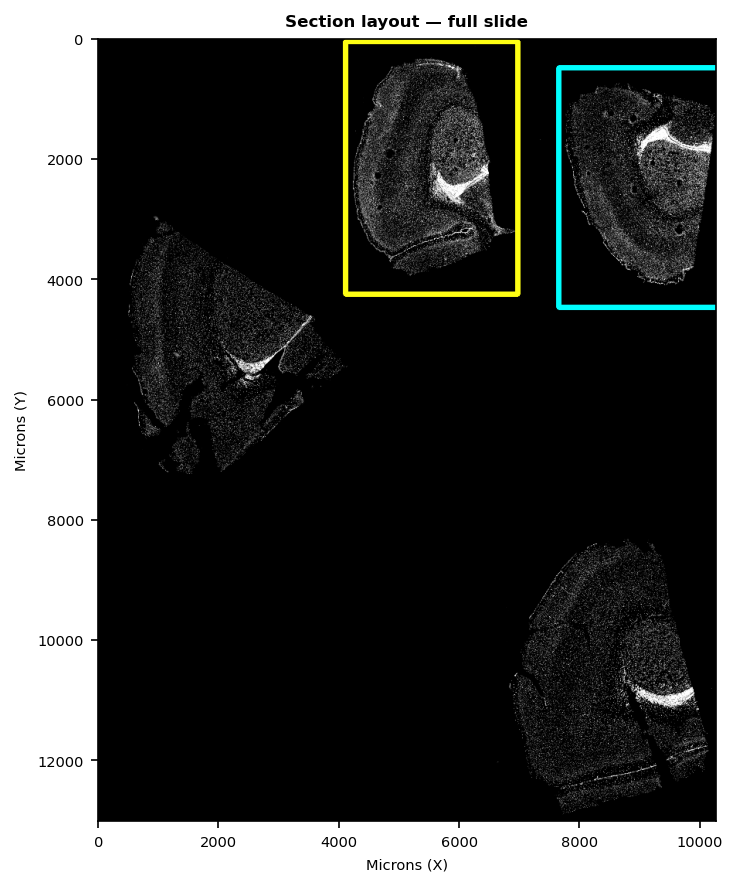

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
from platpy.io_utils import load_sample, save_sample
from platpy.xenium_loader import load_xenium
from platpy.plot_utils import plot_image_grid
from platpy.channels import SampleSet, ROIChannel, OmicChannel
from platpy.viewport import ViewPort
from platpy.transform_utils import aabb_to_poly
from platpy.demo_utils import fetch_zenodo_bundle

# --- UPDATE THIS PATH if you'd like to store the data somewhere else ---
save_dir     = Path.home() / 'platpy_data' / 'XeniumSamples'
sample_names = ['WT_01', 'WT_02']

# --- AUTOMATICALLY DOWNLOAD SAMPLE DATA FROM ZENODO ---
ZENODO = 'https://zenodo.org/records/20320692/files'
for name, fname in [('overview', 'Xenium_overview'),
                    ('WT_01',    'Xenium_WT_01'),
                    ('WT_02',    'Xenium_WT_02')]:
    fetch_zenodo_bundle(save_dir / name, f'{ZENODO}/{fname}.zip')

print("Loading from saved platpy bundles...")
samples = {name: load_sample(save_dir / name) for name in sample_names}
lowres  = load_sample(save_dir / 'overview').images['DAPI']

sample_rois = {
    'WT_01': (4120,  6975,   58, 4252),
    'WT_02': (7651, 10500,  491, 4481),
}
ext = lowres.spatial_meta.extent
vp_overview = ViewPort.create(
    target_width_px=800,
    center_um=((ext[0] + ext[1]) / 2, (ext[2] + ext[3]) / 2),
    fov_um=(ext[1] - ext[0], ext[3] - ext[2])
)
vp_overview.add_layer(lowres).adjust_layer(tint='xkcd:white', percentile_clip=(1, 99))
box_colors = ['xkcd:yellow', 'xkcd:cyan', 'xkcd:bright orange']
for (name, (min_x, max_x, min_y, max_y)), color in zip(sample_rois.items(), box_colors):
    poly = aabb_to_poly(min_x, min_y, max_x, max_y)
    box  = ROIChannel(name=name, polygons={name: poly}).set_style(line_color=color, line_width=5)
    vp_overview.add_layer(box)
plot_image_grid(vp_overview.render(), titles=['Section layout — full slide'], width=5, font_size='small')

print(f"\nReady: {list(samples.keys())}")

### Now let's view our two samples
We will rotate and flip the samples within the viewport so they are matched in appearance.

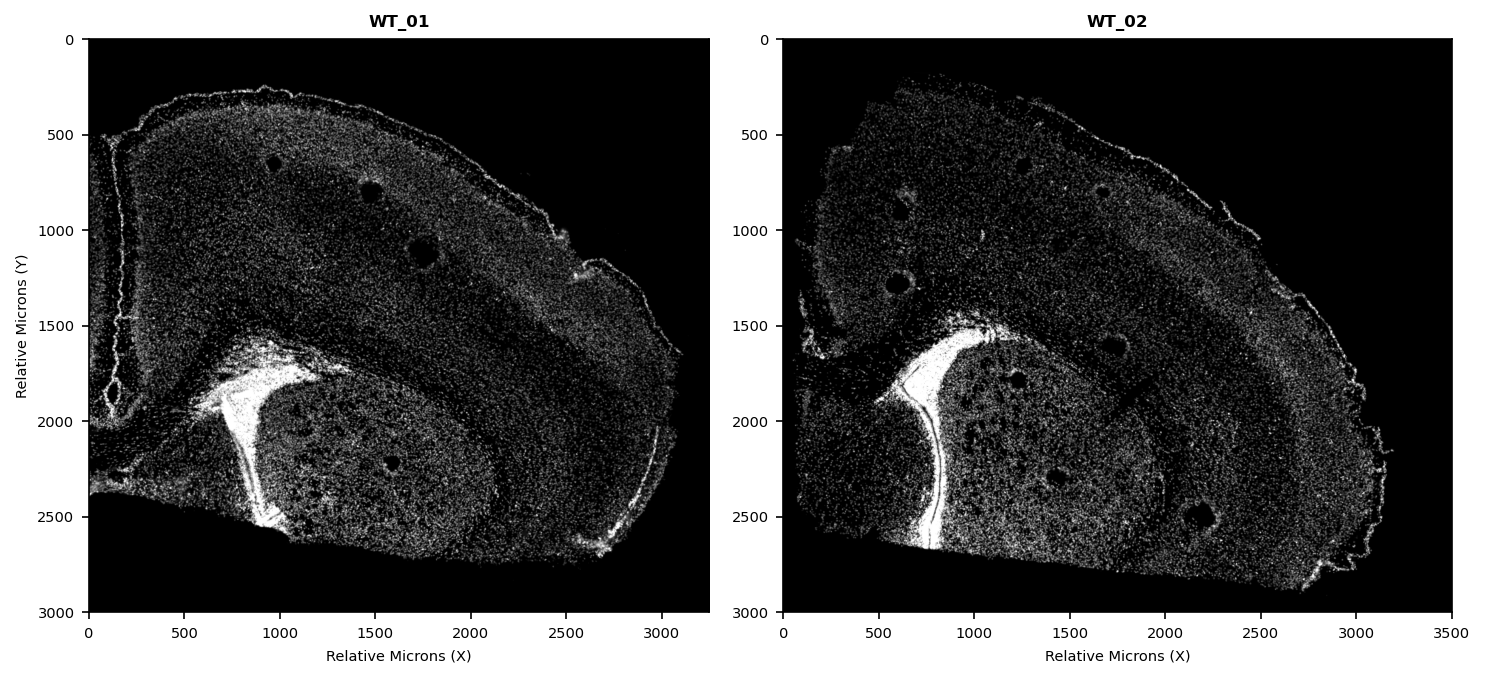

In [2]:
# Lock in the correct orientation for each sample — flip and rotation determined
# from initial inspection. All subsequent sample.viewport() calls inherit these.
samples['WT_01'].view_defaults = {'rotation_deg': 70,  'flip_y': True, 'flip_x': True}
samples['WT_02'].view_defaults = {'rotation_deg': 105, 'flip_y': True}

# Canonical full-section viewports — same API as Visium, different data underneath
vp1 = samples['WT_01'].viewport(center_um=(5250, 1900), fov_um=(3250, 3000))
vp1.add_layer(samples['WT_01'].images['DAPI']).adjust_layer(percentile_clip=(2, 99), gamma=0.8)

vp2 = samples['WT_02'].viewport(center_um=(8800, 2500), fov_um=(3500, 3000))
vp2.add_layer(samples['WT_02'].images['DAPI']).adjust_layer(percentile_clip=(2, 99), gamma=0.8)

plot_image_grid(vp1.render(), vp2.render(), titles=['WT_01', 'WT_02'], columns=2, width=10, font_size='small');

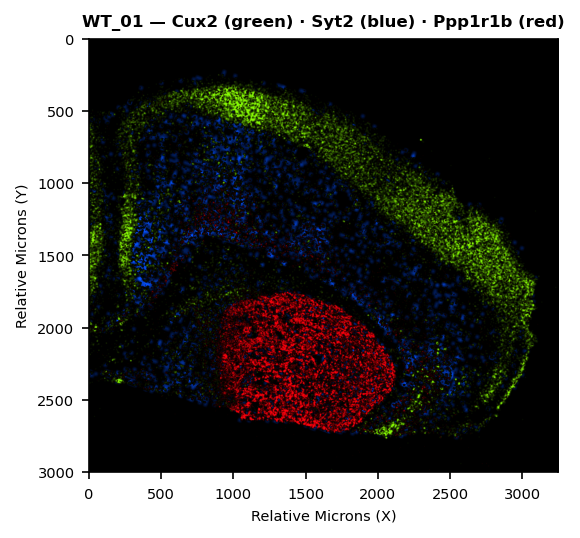

In [3]:
from platpy.channels import OmicChannel

sample = samples['WT_01']

vp_tx = vp1.clone()

vp_tx.adjust_layer(name='DAPI_crop', visible=False)  # Hide the image layer to start

vp_tx.add_layer(sample.omics['transcripts'], name='Syt2')\
               .adjust_omic(gene_name='Syt2', bin_um=20, omic_percentile_clip=(0, 99.9))\
               .adjust_layer(cmap_name = 'if_xkcd:electric blue', percentile_clip=(0, 99), gamma=1.25);

vp_tx.add_layer(sample.omics['transcripts'], name='Cux2')\
               .adjust_omic(gene_name='Cux2', bin_um=8, omic_percentile_clip=(0, 99.9))\
               .adjust_layer(cmap_name = 'if_xkcd:lime green', percentile_clip=(0, 99), gamma=.8, blend_mode='');

vp_tx.add_layer(sample.omics['transcripts'], name='Ppp1r1b')\
               .adjust_omic(gene_name='Ppp1r1b', bin_um=4, omic_percentile_clip=(0, 99.9))\
               .adjust_layer(cmap_name = 'if_xkcd:bright red', percentile_clip=(0, 95), gamma=.8);

plot_image_grid(vp_tx.render(),
                titles=[f'{sample.name} — Cux2 (green) · Syt2 (blue) · Ppp1r1b (red)'],
                width=4, font_size='small');

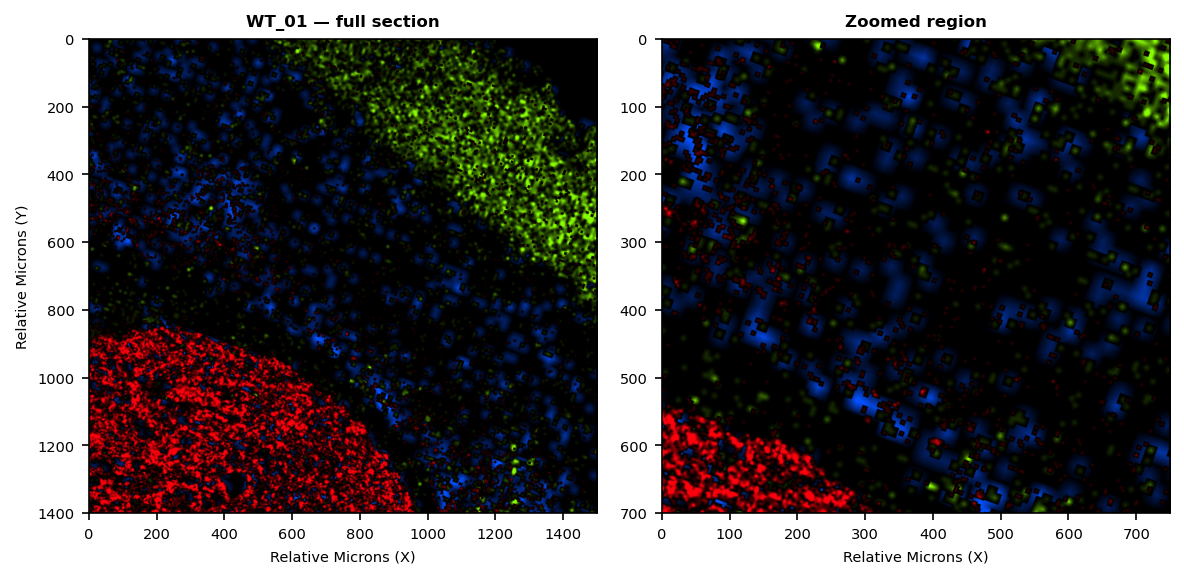

In [4]:
# Zoom into a sub-region — all transcript layers re-render in the new window
# automatically, no coordinate bookkeeping needed.
vp_zoom1 = vp_tx.clone().update_view(center_um=(5250, 1600), fov_um=(1500, 1400) )
vp_zoom2 = vp_tx.clone().update_view(center_um=(5250, 1600), fov_um=(750, 700) )

plot_image_grid(
    [vp_zoom1.render(), vp_zoom2.render()],
    titles=[f'{sample.name} — full section', 'Zoomed region'],
    columns=2, width=8, font_size='small', uniform_size=True
);

#### Platpy handles multi-platform data with the same tools

In this example, you may have noticed a few key things:

- **Xenium and Visium look the same to platpy.** Despite having very different raw formats — Xenium is a point cloud of individual transcripts, Visium is a binned spot matrix — both load into the same SampleSet structure. The ViewPort, DataPort, and all downstream tools work identically on both.
- **Multi-section slides are handled cleanly.** A single Xenium run can capture multiple tissue sections. Platpy loads the full slide once, lets you inspect it, then extracts each section as its own independent SampleSet. Each sample gets its own coordinate system anchored to its physical position on the slide. 
- **Transcript data is handled quickly.** Individual transcripts are sorted by spatial block and stored with a pre-built index, so future analyses can pull just the transcripts from a given region without scanning across the entire slide. You don't need to have the entire gigabyte slide in memory to look at expression in one small bit of tissue.

**Next:** Now that we have both imaging data and transcript-level point clouds in micron space, we can start asking biological questions. In the next section, we'll assign transcripts to cells, build expression matrices, and bring the data into the single-cell analysis ecosystem.

